# Evaluasi dan analisis error Minggu 10

**DATA SINTETIS / SIMULASI. Test historis, bukan holdout baru.**
Notebook membaca prediksi tuning, memeriksa integritas dan sumber, menghitung ulang
metrik, serta menulis tabel/grafik/model card. Tidak melakukan training atau pemilihan ulang.

Signed error = prediksi - aktual (positif: terlalu tinggi). Residual = aktual - prediksi.
Hanya 7 origin, satu per ID. Tidak mengklaim diagnosis, penyebab, atau signifikansi.
Prasyarat: output notebook 05 tersedia. Hasil di `reports/week10_evaluation/`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'backend').is_dir(): ROOT = ROOT.parent
assert (ROOT / 'models/tuning_week10/tuning_manifest.json').is_file()
sys.path.insert(0, str(ROOT))
from etl.evaluate_week10_models import execute
analysis = execute()

Run e34327cd28c78f592900 | 49 pasangan model-origin | 7 origin model terpilih
Bias -1.697 mmHg | under=4, over=3


In [2]:
import pandas as pd
report = ROOT / 'reports/week10_evaluation'
display(pd.read_csv(report / 'metrics_and_bias.csv'))
display(pd.read_csv(report / 'largest_selected_model_errors.csv'))
display(pd.read_csv(report / 'errors_per_respondent.csv'))
print('Model dipilih dari validasi:', analysis['selected_model'])
print(analysis['limitation'])

,model,stage,split,mae,rmse,r2,n,bias,median_absolute_error,max_absolute_error,over_count,under_count,equal_count
0,Naive 7-day mean,reference,historical_test,1.933673,2.234723,0.850309,7,-1.678571,1.642857,4.071429,1,6,0
1,Naive 7-day mean,reference,validation,1.907738,2.376512,0.864637,60,-0.045833,1.732143,6.142857,27,33,0
2,Linear Regression,original,historical_test,2.575492,3.113985,0.709343,7,-1.697332,1.279338,5.136333,3,4,0
3,Linear Regression,selected_configuration,historical_test,2.575492,3.113985,0.709343,7,-1.697332,1.279338,5.136333,3,4,0
4,Linear Regression,selected_configuration,validation,2.180456,2.758826,0.817582,60,-0.082439,1.804311,6.520323,30,30,0
5,Random Forest,original,historical_test,2.959332,3.440747,0.645143,7,-2.208377,3.315310,6.017091,2,5,0
6,Random Forest,selected_configuration,historical_test,2.682003,3.236340,0.686053,7,-1.859594,2.457913,6.406135,1,6,0
7,Random Forest,selected_configuration,validation,2.911711,4.324732,0.551732,60,-0.759465,2.001318,13.541932,30,30,0
8,Hist Gradient Boosting,original,historical_test,3.693402,4.831551,0.300286,7,-3.061395,2.452232,11.018801,1,6,0
9,Hist Gradient Boosting,selected_configuration,historical_test,3.630539,4.651232,0.351540,7,-2.954910,2.466392,10.424076,1,6,0


,model,stage,respondent_id,asof_date,forecast_start,forecast_end,actual,prediction,signed_error,residual,absolute_error,naive_prediction,naive_absolute_error,absolute_error_minus_naive,direction
0,Linear Regression,selected_configuration,SIM009,2026-09-18,2026-09-19,2026-09-25,121.857143,116.720810,-5.136333,5.136333,5.136333,121.178571,0.678571,4.457761,under
1,Linear Regression,selected_configuration,SIM002,2026-09-18,2026-09-19,2026-09-25,122.071429,117.669396,-4.402032,4.402032,4.402032,120.178571,1.892857,2.509175,under
2,Linear Regression,selected_configuration,SIM004,2026-09-18,2026-09-19,2026-09-25,130.321429,126.164388,-4.157040,4.157040,4.157040,128.678571,1.642857,2.514183,under
3,Linear Regression,selected_configuration,SIM017,2026-09-18,2026-09-19,2026-09-25,124.250000,125.529338,1.279338,-1.279338,1.279338,121.250000,3.000000,-1.720662,over
4,Linear Regression,selected_configuration,SIM006,2026-09-18,2026-09-19,2026-09-25,116.035714,114.776239,-1.259476,1.259476,1.259476,116.928571,0.892857,0.366618,under


,model,stage,respondent_id,mae,rmse,r2,n,bias,median_absolute_error,max_absolute_error,over_count,under_count,equal_count,limitation
0,Hist Gradient Boosting,original,SIM001,1.589693,1.589693,NaN,1,-1.589693,1.589693,1.589693,0,1,0,Satu origin per ID; tidak menilai performa sta...
1,Hist Gradient Boosting,original,SIM002,2.808400,2.808400,NaN,1,-2.808400,2.808400,2.808400,0,1,0,Satu origin per ID; tidak menilai performa sta...
2,Hist Gradient Boosting,original,SIM004,11.018801,11.018801,NaN,1,-11.018801,11.018801,11.018801,0,1,0,Satu origin per ID; tidak menilai performa sta...
3,Hist Gradient Boosting,original,SIM006,1.470225,1.470225,NaN,1,-1.470225,1.470225,1.470225,0,1,0,Satu origin per ID; tidak menilai performa sta...
4,Hist Gradient Boosting,original,SIM009,2.452232,2.452232,NaN,1,-2.452232,2.452232,2.452232,0,1,0,Satu origin per ID; tidak menilai performa sta...
5,Hist Gradient Boosting,original,SIM012,2.212025,2.212025,NaN,1,2.212025,2.212025,2.212025,1,0,0,Satu origin per ID; tidak menilai performa sta...
6,Hist Gradient Boosting,original,SIM017,4.302435,4.302435,NaN,1,-4.302435,4.302435,4.302435,0,1,0,Satu origin per ID; tidak menilai performa sta...
7,Hist Gradient Boosting,selected_configuration,SIM001,1.694599,1.694599,NaN,1,-1.694599,1.694599,1.694599,0,1,0,Satu origin per ID; tidak menilai performa sta...
8,Hist Gradient Boosting,selected_configuration,SIM002,2.782703,2.782703,NaN,1,-2.782703,2.782703,2.782703,0,1,0,Satu origin per ID; tidak menilai performa sta...
9,Hist Gradient Boosting,selected_configuration,SIM004,10.424076,10.424076,NaN,1,-10.424076,10.424076,10.424076,0,1,0,Satu origin per ID; tidak menilai performa sta...


Model dipilih dari validasi: Linear Regression
DATA SINTETIS / SIMULASI. Inner GroupKFold memisahkan ID, tetapi kalender fit/validasi dapat beririsan dan target window training berkorelasi. Ini bukan validasi forecasting kronologis penuh. Test CP3 sudah pernah diperiksa; evaluasi ulang bersifat historis, bukan holdout baru. Sampel kecil; bukan validasi klinis atau hasil data aktual. Persetujuan target diasumsikan untuk tugas ini; bukti akademik belum direkam dalam artefak aktif.


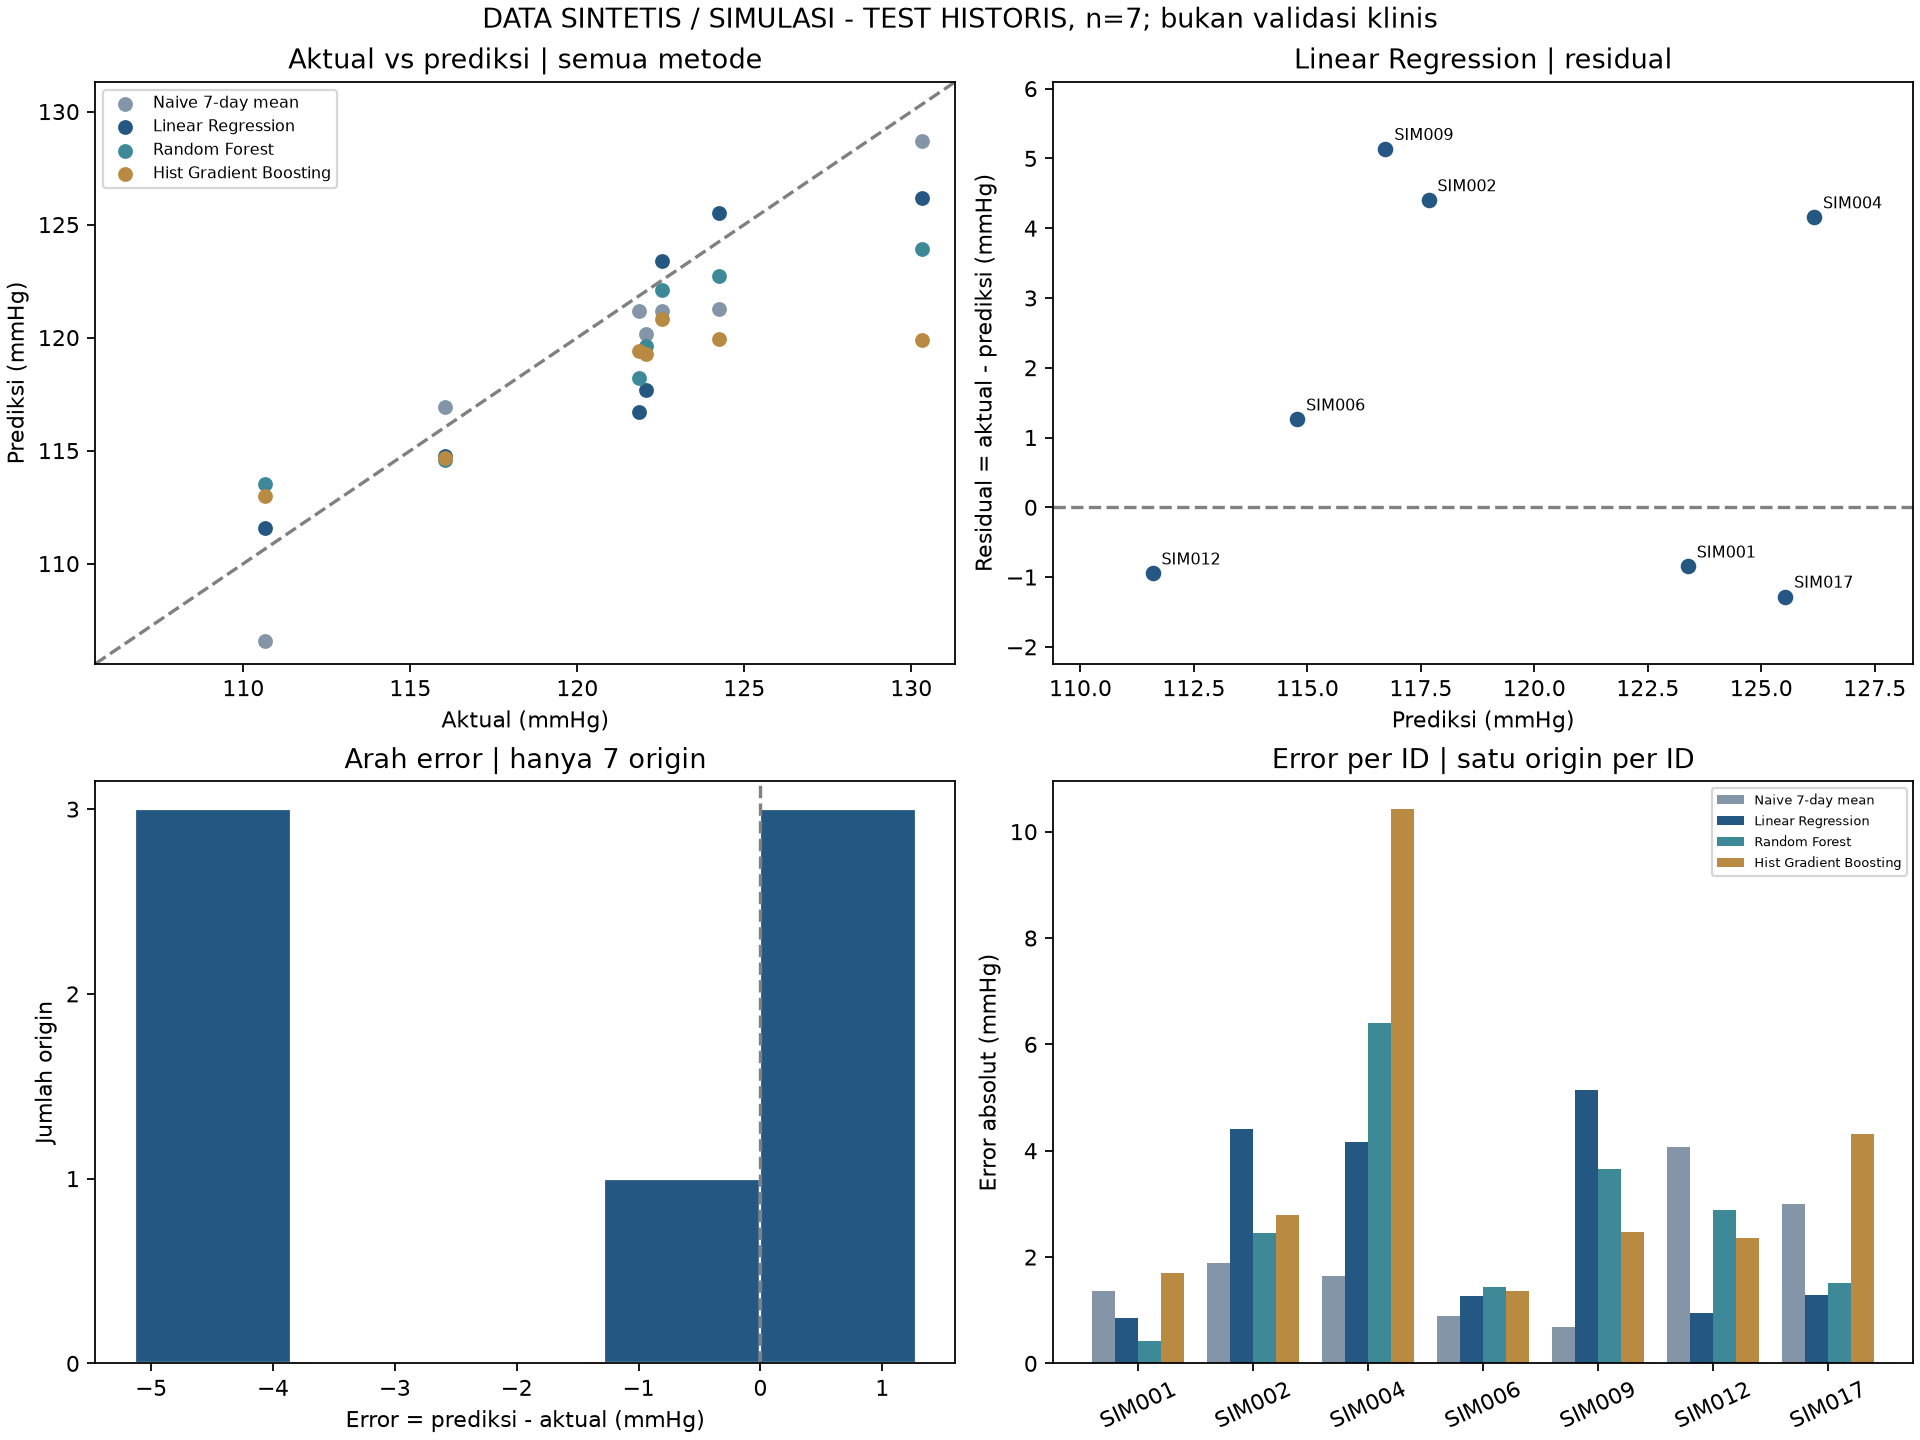

In [3]:
from IPython.display import Image, display
display(Image(filename=str(report / 'figures/error_analysis.png')))

## Membaca hasil
- Bandingkan konfigurasi original/terpilih dengan baseline; model terlatih terbaik
  tidak otomatis mengalahkan naif.
- Bias negatif menunjukkan prediksi rata-rata terlalu rendah pada sampel ini.
- Error terbesar perlu ditelusuri sebagai contoh, bukan penyebab yang sudah terbukti.
- MAE per ID di sini hanya error satu contoh. R2 per ID tidak tersedia.
- Tabel/gambar merupakan bahan hasil simulasi untuk laporan; bukan hasil penelitian aktual.

Laporan lengkap: `docs/WEEK10_EVALUATION_REPORT.md`.